In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("claimants.csv")
df.head(10)

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
5,97,0,1.0,1.0,0.0,35.0,0.309
6,10,0,0.0,1.0,0.0,9.0,3.538
7,36,0,1.0,1.0,0.0,34.0,4.881
8,51,1,1.0,1.0,0.0,60.0,0.874
9,55,1,0.0,1.0,0.0,NaN,0.350


# Initial Data Analysis

In [3]:
df.shape

(1340, 7)

In [4]:
df.dtypes

CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

In [5]:
df.isnull().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,11202.001493,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,9512.750796,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4177.000000,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,8756.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,15702.500000,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


In [8]:
df.nunique()

CASENUM     1283
ATTORNEY       2
CLMSEX         2
CLMINSUR       2
SEATBELT       2
CLMAGE        68
LOSS         916
dtype: int64

In [9]:
cat_cols = ["CLMSEX", "CLMINSUR", "SEATBELT"]
num_cols = ["CLMAGE", "LOSS"]
target = "ATTORNEY"
print("Numerical:", num_cols)
print("Categorical:", cat_cols)
print("Target:", target)

Numerical: ['CLMAGE', 'LOSS']
Categorical: ['CLMSEX', 'CLMINSUR', 'SEATBELT']
Target: ATTORNEY


In [10]:
df[target].value_counts()

ATTORNEY
0    685
1    655
Name: count, dtype: int64

# Data Pre-processing

In [11]:
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])
for c in num_cols:
    df[c] = df[c].fillna(df[c].median())
df = df.drop_duplicates()
df.isnull().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

In [12]:
df = df.drop(columns="CASENUM")
df.shape

(1340, 6)

In [13]:
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [14]:
outliers = df[((df[num_cols] < lower_bound) | (df[num_cols] > upper_bound)).any(axis=1)]
outliers.shape

(69, 6)

In [15]:
df[num_cols] = df[num_cols].clip(lower_bound, upper_bound, axis=1)
df[num_cols].describe()

,CLMAGE,LOSS
count,1340.000000,1340.000000
mean,28.627612,2.369601
std,18.791557,2.570479
min,0.000000,0.000000
25%,10.000000,0.400000
50%,30.000000,1.069500
75%,40.000000,3.781500
max,85.000000,8.853750


In [16]:
df[cat_cols] = df[cat_cols].astype(int)
df.head()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0,0,1,0,50.0,8.85375
1,1,1,0,0,18.0,0.89100
2,1,0,1,0,5.0,0.33000
3,0,0,1,1,31.0,0.03700
4,1,0,1,0,30.0,0.03800


In [17]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
df.head()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0,0,1,0,1.137765,2.523487
1,1,1,0,0,-0.565764,-0.575439
2,1,0,1,0,-1.257822,-0.793767
3,0,0,1,1,0.126295,-0.907796
4,1,0,1,0,0.073059,-0.907407


# Feature Selection

In [18]:
corr = df.corr()[target].drop(target).sort_values()
corr

LOSS       -0.408248
SEATBELT   -0.055848
CLMAGE      0.012471
CLMSEX      0.076564
CLMINSUR    0.076631
Name: ATTORNEY, dtype: float64

In [19]:
features = corr[corr.abs() > 0.05].index.tolist()
features

['LOSS', 'SEATBELT', 'CLMSEX', 'CLMINSUR']

# Logistic Regression

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [21]:
X = df[features]
y = df[target]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(1072, 4) (268, 4)


In [23]:
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [24]:
pd.DataFrame({"Feature": features, "Coefficient": model.coef_[0]})

,Feature,Coefficient
0,LOSS,-1.073594
1,SEATBELT,-0.749637
2,CLMSEX,0.362621
3,CLMINSUR,0.359115


In [25]:
model.intercept_

array([-0.69623239])

# Prediction

In [26]:
y_pred = model.predict(X_test)

# Evaluation

In [27]:
accuracy_score(y_test, y_pred)

0.7350746268656716

In [28]:
cm = confusion_matrix(y_test, y_pred)
pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"])

,Predicted 0,Predicted 1
Actual 0,85,43
Actual 1,28,112


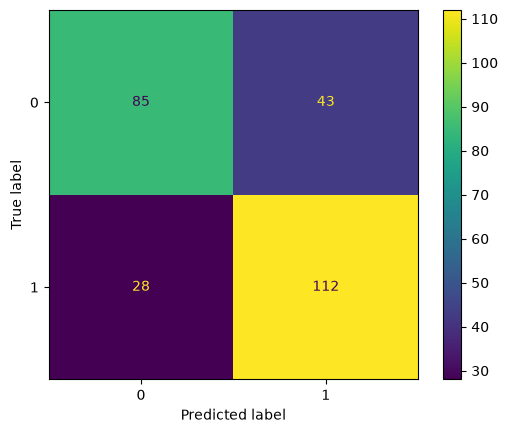

In [29]:
ConfusionMatrixDisplay(cm).plot()
plt.show()

In [30]:
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
comparison.head(15)

,Actual,Predicted
0,0,0
1,0,0
2,1,1
3,0,1
4,0,0
5,0,0
6,1,1
7,0,1
8,0,1
9,0,0
